In [5]:
from google.colab import files

uploaded = files.upload()

Saving Titanic-Dataset.csv to Titanic-Dataset.csv


Mini Project: Titanic Survival Prediction – Data Cleaning Project

Original Dataset Shape: (891, 12)

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Missing Values After Cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

Dataset After Encoding:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name  Sex   Age  SibSp  Parch  \
0                            Braund, Mr. Owen Harris    1  22.0      1      0   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...    0  38.0      1  

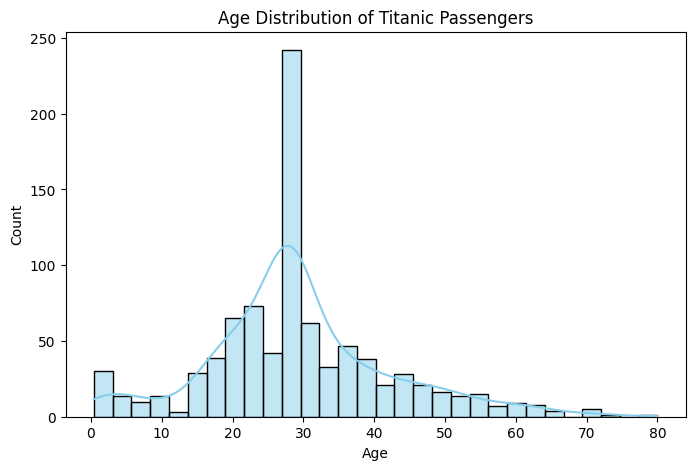


Cleaned dataset saved as Titanic_Cleaned.csv


In [6]:
# Import Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

# Load Dataset
df = pd.read_csv("Titanic-Dataset.csv")

print("Original Dataset Shape:", df.shape)

# ----------------------------
# 1. Check Missing Values
# ----------------------------
print("\nMissing Values:")
print(df.isnull().sum())

# ----------------------------
# 2. Handle Missing Data
# ----------------------------

# Age -> Median Imputation
df['Age'] = df['Age'].fillna(df['Age'].median())

# Embarked -> Mode Imputation
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# Cabin -> Drop column
df.drop(columns=['Cabin'], inplace=True)

# Remaining nulls
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

# ----------------------------
# 3. Encode Sex Column
# ----------------------------

le = LabelEncoder()
df['Sex'] = le.fit_transform(df['Sex'])

# ----------------------------
# 4. Encode Embarked Column
# ----------------------------

df = pd.get_dummies(df,
                    columns=['Embarked'],
                    drop_first=True)

print("\nDataset After Encoding:")
print(df.head())

# ----------------------------
# 5. Visualize Age Distribution
# ----------------------------

plt.figure(figsize=(8,5))
sns.histplot(df['Age'],
             bins=30,
             kde=True,
             color='skyblue')

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

# ----------------------------
# 6. Save Cleaned Dataset
# ----------------------------

df.to_csv("Titanic_Cleaned.csv",
          index=False)

print("\nCleaned dataset saved as Titanic_Cleaned.csv")